# MEMC exercise 8 – Points in a ball and their distance

---

The problem: pick **two independent points $P, Q$ uniformly in the unit ball** (a disc in the plane,
a ball in space) and compute **the expectation of a function of their distance**
$\rho = \|P - Q\|$:

$$J = \frac{1}{V^2}\int_{B}\!\int_{B} f\bigl(\|P - Q\|\bigr)\,dP\,dQ = E\,f(\rho),\qquad P, Q \sim \text{Uniform}(B),$$

where $V$ is the volume of the ball (the factor $1/V^2$ is exactly the normalization to an
expectation). This is a four- (in space six-) dimensional integral, which is a typical Monte Carlo
problem.

The exercise ties together the earlier material and shows three things:

- how to generate **a uniform point in a ball**: by the rejection method (exercise 6) and by **polar
  coordinates** (the inverse transform, exercise 4)
- that the radius **must not** be drawn uniformly, but as $\gamma^{1/d}$
- how **symmetry** saves half of the random numbers

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def estimate(sampler, n):
    '''Plain Monte Carlo: the average of n calls of the generator and its standard error sigma/sqrt(n).'''
    s = s2 = 0.0
    for _ in range(n):
        x = sampler()
        s += x
        s2 += x * x
    mean = s / n
    var = max(s2 / n - mean * mean, 0.0)
    return mean, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    '''Prints the estimate and verifies it lies within k standard errors of the exact value.'''
    print(f"{name}: {mean:.5f} +- {se:.5f}  (exact {exact:.5f})")
    assert abs(mean - exact) <= k * se, name


def distance(P, Q):
    return math.sqrt(sum((p - q) ** 2 for p, q in zip(P, Q)))

What the problem looks like: in the unit disc we pick **pairs** of points $P, Q$ at random and
measure their distance $\rho$ (the segment). What we are after is the expectation of $f(\rho)$ over
all pairs.

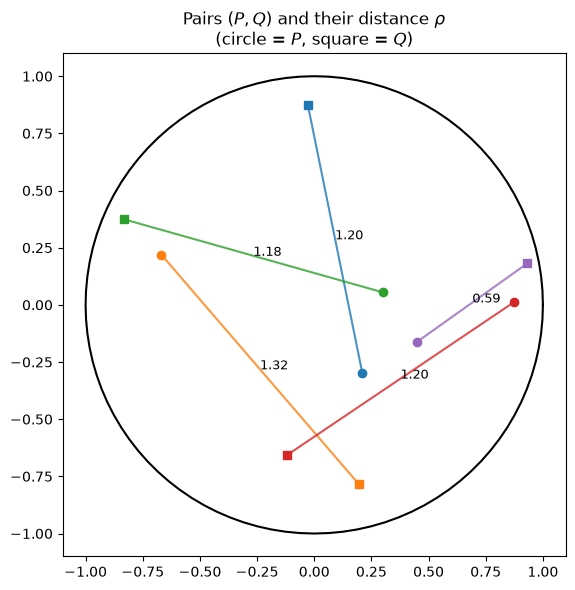

In [2]:
fig, ax = plt.subplots(figsize=(6.5, 6.0))
ax.plot([math.cos(t / 100 * 2 * math.pi) for t in range(101)], [math.sin(t / 100 * 2 * math.pi) for t in range(101)], "k")
for k in range(5):
    pts = []
    for _ in range(2):
        r, phi = math.sqrt(random.random()), 2 * math.pi * random.random()
        pts.append((r * math.cos(phi), r * math.sin(phi)))
    (px, py), (qx, qy) = pts
    ax.plot([px, qx], [py, qy], color=f"C{k}", alpha=0.8)
    ax.plot([px], [py], "o", color=f"C{k}")
    ax.plot([qx], [qy], "s", color=f"C{k}")
    ax.text((px + qx) / 2, (py + qy) / 2, f"{math.hypot(px - qx, py - qy):.2f}", fontsize=9)
ax.set_aspect("equal")
ax.set_title("Pairs $(P, Q)$ and their distance " + r"$\rho$" + "\n(circle = $P$, square = $Q$)")
plt.tight_layout()
plt.show()

## 1. The exact values (so that we have something to compare against)

For $f(\rho) = \rho^2$ the result comes out easily by hand. For independent $P, Q$,

$$E\|P - Q\|^2 = E\|P\|^2 + E\|Q\|^2 - 2\,E(P\cdot Q) = 2\,E\|P\|^2,$$

because $E(P\cdot Q) = EP \cdot EQ = 0$ (the centre of the ball is the centroid). The radius
$r = \|P\|$ has, in $d$ dimensions, the density $d\,r^{d-1}$ on $[0,1]$ (the area of the sphere grows
like $r^{d-1}$), and hence $E\,r^2 = \dfrac{d}{d+2}$. The result:

$$E\,\rho^2 = \frac{2d}{d+2}\quad\Longrightarrow\quad d = 2:\ 1,\qquad d = 3:\ \tfrac65 = 1.2.$$

For $f(\rho) = \rho$ the integral is harder; the known values are

$$d = 2:\ E\rho = \frac{128}{45\pi} \approx 0.9054,\qquad d = 3:\ E\rho = \frac{36}{35} \approx 1.0286.$$

In [3]:
exact = {
    ("rho", 2): 128 / (45 * math.pi),
    ("rho", 3): 36 / 35,
    ("rho2", 2): 1.0,
    ("rho2", 3): 1.2,
}
for k, v in exact.items():
    print(k, f"{v:.6f}")

('rho', 2) 0.905415
('rho', 3) 1.028571
('rho2', 2) 1.000000
('rho2', 3) 1.200000


## 2. A uniform point in a ball: the rejection method

We already know a uniform point in a ball from exercise 6: take the **cube** $[-1,1]^d$, a uniform
point in it, and accept it only when $\|x\| < 1$. The density of the target distribution is constant
on the ball, and so the accepted points are uniform in the ball.

The acceptance probability is the ratio of the volumes $V_d / 2^d$. In the plane
$\pi/4 \approx 78.5\,\%$, in space $\pi/6 \approx 52.4\,\%$. But it **falls off sharply** with the
dimension:

In [4]:
def sample_unit_ball(d=2):
    '''The rejection method in the cube [-1, 1]^d.'''
    while True:
        x = [2 * random.random() - 1 for _ in range(d)]
        if sum(c * c for c in x) < 1:
            return x


def ball_volume(d):
    return math.pi ** (d / 2) / math.gamma(d / 2 + 1)


print(f"{'d':>3s} {'V_d':>10s} {'acceptance V_d / 2^d':>22s} {'tries per point':>17s}")
for d in (2, 3, 4, 5, 8, 10, 15, 20):
    p = ball_volume(d) / 2 ** d
    print(f"{d:3d} {ball_volume(d):10.4f} {p:22.2e} {1 / p:17.1f}")

# a check by experiment for d = 2, 3, 5
for d in (2, 3, 5):
    tries = 0
    accepted = 0
    while accepted < 20_000:
        tries += 1
        if sum((2 * random.random() - 1) ** 2 for _ in range(d)) < 1:
            accepted += 1
    print(f"d = {d}: measured acceptance probability {accepted / tries:.4f}, theory {ball_volume(d) / 2 ** d:.4f}")

  d        V_d   acceptance V_d / 2^d   tries per point
  2     3.1416               7.85e-01               1.3
  3     4.1888               5.24e-01               1.9
  4     4.9348               3.08e-01               3.2
  5     5.2638               1.64e-01               6.1
  8     4.0587               1.59e-02              63.1
 10     2.5502               2.49e-03             401.5
 15     0.3814               1.16e-05           85905.3
 20     0.0258               2.46e-08        40631627.6
d = 2: measured acceptance probability 0.7802, theory 0.7854
d = 3: measured acceptance probability 0.5236, theory 0.5236
d = 5: measured acceptance probability 0.1638, theory 0.1645


Already at $d = 10$ we reject about $400$ out of every $401$ tries, and at $d = 20$ it is a disaster.
For two or three dimensions the rejection method is fine; otherwise we need something better: to
**generate the point in the ball directly**.

## 3. Polar coordinates: the inverse transform

We specify a point in the ball by its **radius $r$** and its **direction** (an angle). We generate
both parts independently.

### The radius: $r = \gamma^{1/d}$, not $\gamma$

The radius has the density $d\,r^{d-1}$, because the thin shell $[r, r+dr]$ has a volume proportional
to $r^{d-1}\,dr$. The distribution function is $F(r) = r^d$ and inverting it (exercise 4) gives

$$r = \gamma^{1/d}.$$

So **not** $r = \gamma$! A uniformly drawn radius would put too many points near the centre (there is
little area there, but a lot of points). The picture shows it.

### The direction

- **The plane:** the angle $\varphi \sim R(0, 2\pi)$, the point $(r\cos\varphi,\ r\sin\varphi)$.
- **Space:** Archimedes' theorem: on the sphere, $z = \cos\theta$ is **uniform on $[-1,1]$** (the area
  of a band between two parallel planes depends only on their separation) and
  $\varphi \sim R(0, 2\pi)$. The point is
  $r\bigl(\sqrt{1-z^2}\cos\varphi,\ \sqrt{1-z^2}\sin\varphi,\ z\bigr)$.
- **A general dimension:** a vector of $d$ independent $N(0,1)$ variables is rotationally symmetric,
  so after normalizing it to length $1$ it gives a uniform direction on the sphere (Marsaglia /
  Muller).

In [5]:
def sample_unit_ball_polar(d=2):
    '''Polar coordinates for d = 2, 3: a fixed number of random numbers, no rejection.'''
    r = random.random() ** (1 / d)
    phi = 2 * math.pi * random.random()
    if d == 2:
        return [r * math.cos(phi), r * math.sin(phi)]
    z = 2 * random.random() - 1  # Archimedes: cos(theta) is uniform on [-1, 1]
    s = math.sqrt(1 - z * z)
    return [r * s * math.cos(phi), r * s * math.sin(phi), r * z]


def sample_unit_ball_gauss(d=2):
    '''Any d: the direction from a normalized Gaussian vector, the radius γ^(1/d).'''
    g = [random.gauss(0, 1) for _ in range(d)]
    norm = math.sqrt(sum(c * c for c in g))
    r = random.random() ** (1 / d)
    return [r * c / norm for c in g]


# the test: the fraction of points with ||x|| < 1/2 should be (1/2)^d (the ratio of the ball volumes)
n = 100_000
for d in (2, 3):
    for gen in (sample_unit_ball, sample_unit_ball_polar, sample_unit_ball_gauss):
        m, se = estimate(lambda: float(sum(c * c for c in gen(d)) < 0.25), n)
        check(f"d = {d}, {gen.__name__:22s} P(||x|| < 1/2)", m, se, 0.5 ** d)

d = 2, sample_unit_ball       P(||x|| < 1/2): 0.24873 +- 0.00137  (exact 0.25000)


d = 2, sample_unit_ball_polar P(||x|| < 1/2): 0.24947 +- 0.00137  (exact 0.25000)


d = 2, sample_unit_ball_gauss P(||x|| < 1/2): 0.25087 +- 0.00137  (exact 0.25000)


d = 3, sample_unit_ball       P(||x|| < 1/2): 0.12394 +- 0.00104  (exact 0.12500)
d = 3, sample_unit_ball_polar P(||x|| < 1/2): 0.12429 +- 0.00104  (exact 0.12500)


d = 3, sample_unit_ball_gauss P(||x|| < 1/2): 0.12513 +- 0.00105  (exact 0.12500)


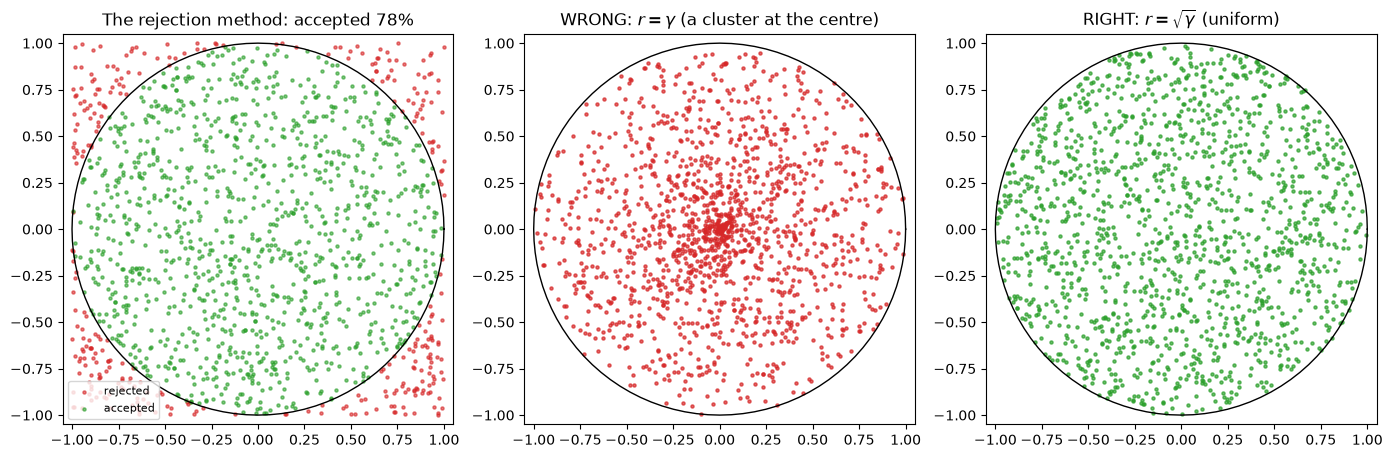

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.7))
circle = [(math.cos(t / 100 * 2 * math.pi), math.sin(t / 100 * 2 * math.pi)) for t in range(101)]
M = 1500

# 1) the rejection method
acc, rej = [], []
for _ in range(M):
    x = (2 * random.random() - 1, 2 * random.random() - 1)
    (acc if x[0] ** 2 + x[1] ** 2 < 1 else rej).append(x)
axes[0].scatter(*zip(*rej), s=5, c="tab:red", alpha=0.6, label="rejected")
axes[0].scatter(*zip(*acc), s=5, c="tab:green", alpha=0.6, label="accepted")
axes[0].set_title(f"The rejection method: accepted {len(acc) / M:.0%}")
axes[0].legend(loc="lower left", fontsize=8)

# 2) wrong: r = γ
wrong = []
for _ in range(M):
    r, phi = random.random(), 2 * math.pi * random.random()
    wrong.append((r * math.cos(phi), r * math.sin(phi)))
axes[1].scatter(*zip(*wrong), s=5, c="tab:red", alpha=0.7)
axes[1].set_title("WRONG: $r = \\gamma$ (a cluster at the centre)")

# 3) right: r = sqrt(γ)
right = [sample_unit_ball_polar(2) for _ in range(M)]
axes[2].scatter(*zip(*right), s=5, c="tab:green", alpha=0.7)
axes[2].set_title(r"RIGHT: $r = \sqrt{\gamma}$ (uniform)")

for ax in axes:
    ax.plot(*zip(*circle), "k", lw=1)
    ax.set_aspect("equal")
    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
plt.tight_layout()
plt.show()

In the middle you can see the mistake that is worth remembering: the same number of points on a
smaller area means a higher density. The correct radius $\sqrt{\gamma}$ ($d = 2$) evens that density
out.

## 4. Estimating $J$ for two points in a ball

Now the problem itself: we compute the average of $f(\|P-Q\|)$ for two independent points, for both
functions $f$ and both generators.

In [7]:
def pair_mean(f, d, sampler, n):
    return estimate(lambda: f(distance(sampler(d), sampler(d))), n)


n = 100_000
for label, f, key in (("rho  ", lambda r: r, "rho"), ("rho^2", lambda r: r * r, "rho2")):
    for d in (2, 3):
        for gen in (sample_unit_ball, sample_unit_ball_polar):
            check(f"f = {label}  d = {d}  {gen.__name__:22s}", *pair_mean(f, d, gen, n), exact[(key, d)])

f = rho    d = 2  sample_unit_ball      : 0.90657 +- 0.00134  (exact 0.90541)
f = rho    d = 2  sample_unit_ball_polar: 0.90611 +- 0.00134  (exact 0.90541)


f = rho    d = 3  sample_unit_ball      : 1.02712 +- 0.00120  (exact 1.02857)
f = rho    d = 3  sample_unit_ball_polar: 1.02756 +- 0.00119  (exact 1.02857)


f = rho^2  d = 2  sample_unit_ball      : 0.99781 +- 0.00257  (exact 1.00000)
f = rho^2  d = 2  sample_unit_ball_polar: 0.99521 +- 0.00257  (exact 1.00000)


f = rho^2  d = 3  sample_unit_ball      : 1.19888 +- 0.00248  (exact 1.20000)
f = rho^2  d = 3  sample_unit_ball_polar: 1.19554 +- 0.00248  (exact 1.20000)


In [8]:
# the speed of the generators (one point)
m = 100_000
print(f"{'generator':26s} {'d':>2s} {'time per point':>15s}")
for d in (2, 3):
    for gen in (sample_unit_ball, sample_unit_ball_polar, sample_unit_ball_gauss):
        t0 = time.perf_counter()
        for _ in range(m):
            gen(d)
        print(f"{gen.__name__:26s} {d:2d} {(time.perf_counter() - t0) / m * 1e6:12.2f} us")

generator                   d  time per point
sample_unit_ball            2         0.56 us
sample_unit_ball_polar      2         0.27 us


sample_unit_ball_gauss      2         0.96 us
sample_unit_ball            3         0.95 us


sample_unit_ball_polar      3         0.39 us


sample_unit_ball_gauss      3         1.25 us


Already at $d = 2, 3$ polar coordinates are a couple of times faster than rejection and they have a
**fixed cost** (no loop). The Gaussian generator is slower in low dimensions (it generates normal
numbers), but it works in every dimension, and where rejection breaks down it is indispensable.

## 5. Symmetry: how many random numbers do we really need?

The function $f(\|P-Q\|)$ depends only on **the distance**, not on where the pair sits in space. If we
rotate both points by the same rotation, the distance does not change and neither does the
distribution of the pair $(P, Q)$. So we may **rotate $P$ onto an axis** (in space onto the north
pole, in the plane onto the $x$ axis). What is left is only **the angle between $P$ and $Q$**.

In space: $\mu = \cos\theta$ is uniform on $[-1,1]$ (Archimedes, as above), and by **the law of
cosines**

$$\rho^2 = r_P^2 + r_Q^2 - 2\,r_P\,r_Q\,\mu.$$

In the plane the angle is $\varphi \sim R(0, 2\pi)$ and instead of $\mu$ we have $\cos\varphi$.

The radii $r_P, r_Q$ are independent with density $d\,r^{d-1}$, i.e. $\gamma^{1/d}$ each. The count of
random numbers: **3 instead of 6** (in space), resp. **3 instead of 4** (in the plane).

In [9]:
def rho_symmetry(d):
    '''The distance of two uniform points in a ball (d = 2, 3) using symmetry: P is on the axis.'''
    rp = random.random() ** (1 / d)
    rq = random.random() ** (1 / d)
    if d == 3:
        mu = 2 * random.random() - 1          # cos(theta) is uniform on [-1, 1]
    else:
        mu = math.cos(2 * math.pi * random.random())
    rho2 = rp * rp + rq * rq - 2 * rp * rq * mu
    return math.sqrt(max(rho2, 0.0))          # max: protection against -1e-17 from rounding errors


n = 100_000
for label, f, key in (("rho  ", lambda r: r, "rho"), ("rho^2", lambda r: r * r, "rho2")):
    for d in (2, 3):
        check(f"f = {label}  d = {d}  symmetry", *estimate(lambda: f(rho_symmetry(d)), n), exact[(key, d)])

# the speed
m = 100_000
for d in (2, 3):
    t0 = time.perf_counter()
    for _ in range(m):
        rho_symmetry(d)
    t_sym = (time.perf_counter() - t0) / m
    t0 = time.perf_counter()
    for _ in range(m):
        distance(sample_unit_ball_polar(d), sample_unit_ball_polar(d))
    t_full = (time.perf_counter() - t0) / m
    print(f"d = {d}: symmetry {t_sym * 1e6:.2f} us, the full pair (polar) {t_full * 1e6:.2f} us  ({t_full / t_sym:.1f}x slower)")

f = rho    d = 2  symmetry: 0.90330 +- 0.00134  (exact 0.90541)
f = rho    d = 3  symmetry: 1.02721 +- 0.00119  (exact 1.02857)


f = rho^2  d = 2  symmetry: 0.99783 +- 0.00258  (exact 1.00000)
f = rho^2  d = 3  symmetry: 1.20261 +- 0.00249  (exact 1.20000)


d = 2: symmetry 0.39 us, the full pair (polar) 1.01 us  (2.6x slower)


d = 3: symmetry 0.35 us, the full pair (polar) 1.34 us  (3.8x slower)


Careful: symmetry does not change the **variance** of $f(\rho)$ (the distribution of $\rho$ is the
same, we only generate it more cheaply), so at the same $N$ the error is the same and what we win is
**cost**. Let us convince ourselves that the distribution of the distance really is the same, and have
a look at what it looks like.

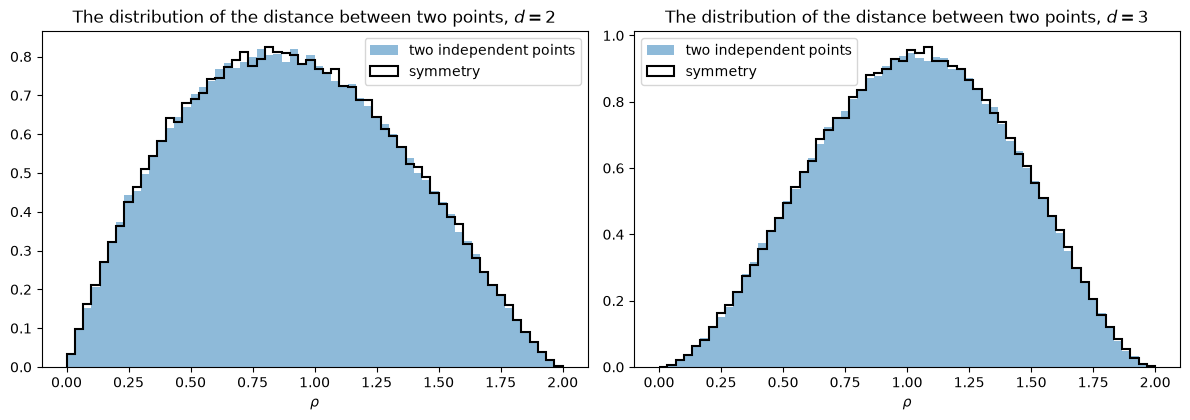

d = 3: E rho (full) = 1.0282, (symmetry) = 1.0288, exact 1.0286
d = 2: E rho (full) = 0.9063, (symmetry) = 0.9058, exact 0.9054


In [10]:
N = 200_000
full3 = [distance(sample_unit_ball_polar(3), sample_unit_ball_polar(3)) for _ in range(N)]
sym3 = [rho_symmetry(3) for _ in range(N)]
full2 = [distance(sample_unit_ball_polar(2), sample_unit_ball_polar(2)) for _ in range(N)]
sym2 = [rho_symmetry(2) for _ in range(N)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for ax, full, sym, d in ((axes[0], full2, sym2, 2), (axes[1], full3, sym3, 3)):
    ax.hist(full, bins=60, range=(0, 2), density=True, alpha=0.5, label="two independent points")
    ax.hist(sym, bins=60, range=(0, 2), density=True, histtype="step", lw=1.5, color="k", label="symmetry")
    ax.set_title(f"The distribution of the distance between two points, $d = {d}$")
    ax.set_xlabel(r"$\rho$")
    ax.legend()
plt.tight_layout()
plt.show()

print(f"d = 3: E rho (full) = {sum(full3) / N:.4f}, (symmetry) = {sum(sym3) / N:.4f}, exact {36 / 35:.4f}")
print(f"d = 2: E rho (full) = {sum(full2) / N:.4f}, (symmetry) = {sum(sym2) / N:.4f}, exact {128 / (45 * math.pi):.4f}")

The histograms coincide. In the plane you can also see that the distance $\rho$ never exceeds the
diameter $2$.

## 6. Higher dimensions

The Gaussian generator works in any dimension. For $f(\rho) = \rho^2$ we know
$E\rho^2 = \dfrac{2d}{d+2}$ for **every** $d$, so let us check $d = 10$, say, where the rejection
method would need over $400$ tries per point.

In [11]:
n = 30_000
for d in (4, 10, 20):
    check(f"d = {d:2d}: E rho^2", *pair_mean(lambda r: r * r, d, sample_unit_ball_gauss, n), 2 * d / (d + 2))

d =  4: E rho^2: 1.32684 +- 0.00427  (exact 1.33333)


d = 10: E rho^2: 1.66502 +- 0.00325  (exact 1.66667)


d = 20: E rho^2: 1.81912 +- 0.00247  (exact 1.81818)


As the dimension grows, $E\rho^2 \to 2$: almost all the points lie close to the **surface** of the
ball ($E\,r^2 = d/(d+2) \to 1$) and two such points are almost always nearly perpendicular, so
$\rho \approx \sqrt 2$. This is one of the manifestations of the "curse of dimensionality".

## 7. An alternative: NumPy

The vectorized version manages a million pairs in a fraction of a second:

In [12]:
try:
    import numpy as np

    rng = np.random.default_rng(1)
    N = 1_000_000

    def points_in_ball(N, d):
        g = rng.standard_normal((N, d))
        g /= np.linalg.norm(g, axis=1, keepdims=True)
        return g * (rng.random(N) ** (1 / d))[:, None]

    for d in (2, 3):
        rho = np.linalg.norm(points_in_ball(N, d) - points_in_ball(N, d), axis=1)
        print(f"d = {d}: E rho = {rho.mean():.5f} +- {rho.std(ddof=1) / np.sqrt(N):.5f} (exact {exact[('rho', d)]:.5f}),"
              f"  E rho^2 = {np.mean(rho ** 2):.5f} (exact {exact[('rho2', d)]:.5f})")
except ModuleNotFoundError:
    print("NumPy is not installed, run:  uv sync")

d = 2: E rho = 0.90551 +- 0.00042 (exact 0.90541),  E rho^2 = 1.00014 (exact 1.00000)


d = 3: E rho = 1.02823 +- 0.00038 (exact 1.02857),  E rho^2 = 1.19946 (exact 1.20000)


## Summary

| Concept | What to remember |
|---------|------------------|
| A uniform point in a ball, by rejection | a point in the cube $[-1,1]^d$, accept when $\|x\|<1$; the acceptance $V_d/2^d$ falls with the dimension |
| Polar coordinates | the radius $r = \gamma^{1/d}$ (inverting $F(r) = r^d$), the direction uniform |
| The direction in the plane / in space / in general | $\varphi \sim R(0,2\pi)$ / Archimedes: $z \sim R(-1,1)$ and $\varphi$ / a normalized Gaussian vector |
| A common mistake | $r = \gamma$ instead of $\gamma^{1/d}$ → a cluster at the centre |
| Symmetry | rotate $P$ onto an axis; what is left is the angle between $P$ and $Q$ and the law of cosines; 3 random numbers instead of 6 |
| The exact values | $E\rho^2 = 2d/(d+2)$; $E\rho = 128/(45\pi)$ ($d=2$), $36/35$ ($d=3$) |

### Try it yourself

1. **The one-dimensional case:** $P, Q \sim R(-1,1)$. Derive $E|P-Q| = \tfrac23$ and
   $E\rho^2 = \tfrac23$ (from the general formula $2d/(d+2)$ at $d=1$) and verify it by simulation.
   Does the radius formula $\gamma^{1/d}$ hold for $d = 1$?
2. Estimate $P(\rho < 1)$ for $d = 2$ and $d = 3$ in three ways: by rejection, by polar coordinates
   and by symmetry. Which is the fastest for the same error?
3. Derive the acceptance probability of the rejection method for $d = 5$ from
   $V_5 = \dfrac{8\pi^2}{15}$ and verify it by simulation (it came out at $\approx 16\,\%$).
4. Estimate $E\,\rho^4$ for $d = 2$ (the `rho_symmetry` function) and then compute it by hand from
   $\rho^2 = \|P\|^2 + \|Q\|^2 - 2P\cdot Q$ (the result should be $5/3$).